# Describing a Table

This notebook accompanies the handout of the same name. The setup cell below writes the register.
Nothing has to be downloaded first. The cells run in order from the top.

The register holds 9000 customer records with eight columns. Four are numeric (`age`, `income`,
`tenure_months`, `score`) and three are categorical (`region`, `plan`, `channel`). The eighth,
`churn`, is the label, 1 for a customer who left and 0 for one who stayed. Three of the numeric
columns have missing values. The data is synthetic and generated from a fixed seed. Every number
below is therefore reproducible.

In [ ]:
#@title Setup: write register.csv  { display-mode: "form" }
# Writes register.csv, the table every cell below reads: eight columns, the label churn last.
import base64, csv, gzip, io, os
import numpy as np
import matplotlib.pyplot as plt

_BLOB = (
    "..."
    "uuD6BQA="
)

if not os.path.exists("register.csv"):
    with open("register.csv", "wb") as f:
        f.write(gzip.decompress(base64.b64decode(_BLOB)))

print("register.csv:", os.path.getsize("register.csv") // 1024, "KB")

register.csv: 382 KB


## 01 Reading a delimited file

A CSV file stores every field as text, the numbers included. Nothing in the file records its encoding. We therefore decide ourselves what type each column has and which encoding to read the file with. We read the register with the `csv` module and convert its columns into NumPy arrays, either one per column or one for the whole table.

In [ ]:
# The first three lines, exactly as they sit on disk.
# newline="" switches off newline translation, so the line endings show as they are.
with open("register.csv", newline="", encoding="utf-8") as f:
    for _ in range(3):
        print(repr(f.readline()))

# The same first line read without it: \r\n has already become \n.
print()
print(repr(open("register.csv", encoding="utf-8").readline()))

'age,income,tenure_months,score,region,plan,channel,churn\r\n'
'38,22207.56,47,59.5,North,standard,online,0\r\n'
',47425.23,36,50.6,Eastfield,premium,shop,0\r\n'

'age,income,tenure_months,score,region,plan,channel,churn\n'


The second record starts with a comma. Its age is missing. A missing value is an empty string. The lines end with `\r\n`. That is what `csv.writer` writes by default.

In [ ]:
with open("register.csv", newline="", encoding="utf-8") as f:
    records = list(csv.DictReader(f))

print(len(records), "rows")
print("columns:", list(records[0]))
print("first row:", records[0])

9000 rows
columns: ['age', 'income', 'tenure_months', 'score', 'region', 'plan', 'channel', 'churn']
first row: {'age': '38', 'income': '22207.56', 'tenure_months': '47', 'score': '59.5', 'region': 'North', 'plan': 'standard', 'channel': 'online', 'churn': '0'}


The csv module does its own line-ending handling. Its documentation therefore specifies `newline=""` for any file passed to it. On a file like this one the parsed rows are identical either way. The difference shows in a quoted field that contains a newline of its own. On writing, the translation can also add a stray `\r`.

### CSV conventions and RFC 4180

There is no CSV standard that every writer follows. RFC 4180 describes the common form. Most tools approximate it:

- Fields are separated by a delimiter, usually a comma. Files written where the comma is the decimal separator use a semicolon. A TSV file uses a tab.
- A field containing the delimiter, a quotation mark or a newline is wrapped in quotation marks.
- A quotation mark inside a quoted field is written twice.
- The first line is a header by convention. Nothing in the file marks it as one.

None of that is enforced. Splitting a line on the delimiter does not take the quoting into account. It also splits the quoted fields that contain the delimiter.

In [ ]:
import io

line = 'Smith, John,42,"Oxford, Oxfordshire"'

print("split ", line.split(","), "->", len(line.split(",")), "fields")
print("csv   ", next(csv.reader([line])), "->", len(next(csv.reader([line]))), "fields")

split  ['Smith', ' John', '42', '"Oxford', ' Oxfordshire"'] -> 5 fields
csv    ['Smith', ' John', '42', 'Oxford, Oxfordshire'] -> 4 fields


The other two rules have the same consequence. A doubled quotation mark is one character, not two. A newline inside a quoted field does not end the record.

In [ ]:
doubled = 'id,note\n7,"she said ""no"" twice"\n'
print(list(csv.reader(io.StringIO(doubled)))[1])

wrapped = 'id,note\n7,"line one\nline two"\n'
print(len(list(csv.reader(io.StringIO(wrapped)))), "records, but",
      len(wrapped.strip().split("\n")), "lines")

['7', 'she said "no" twice']
2 records, but 3 lines


The csv module implements all three rules. A CSV is therefore read through it rather than through `str.split`.

### Types, encoding and missing-value markers

Three things have to come from outside the file. A wrong assumption about any of them raises no error.

- **The types.** Every field is text. That `38` is an age and `59.5` a score is a decision made by
 the reader.
- **The encoding.** Nothing in a CSV records whether it is UTF-8 or something older. A name with an accent is either decoded correctly or turns into wrong characters, depending on what the reader assumed.
- **What counts as missing.** An empty field is one convention. `NA`, `NULL`, `-999` and `-1` are others. Code that does not check for them loads such a marker as a number and averages it.

In [ ]:
region = np.array([r["region"] for r in records])
tenure = np.array([float(r["tenure_months"]) for r in records])

print("region:", region.dtype, region.shape, region[:3])
print("tenure:", tenure.dtype, tenure.shape, tenure[:3])

region: <U9 (9000,) ['North' 'Eastfield' 'Midland']
tenure: float64 (9000,) [47. 36. 32.]


In [ ]:
# The same conversion fails on a column with empty fields.
try:
    income_broken = np.array([float(r["income"]) for r in records])
except ValueError as e:
    print("ValueError:", e)

ValueError: could not convert string to float: ''


### Mixed column types

`np.loadtxt` and `np.genfromtxt` read a delimited file straight into an array. They fit a file that is numeric throughout. This file is not. One array holds one dtype. A table with text and numbers in it therefore has to become either several arrays or one array of strings. An array of strings cannot be averaged.

In [ ]:
# the whole table as one array of strings
as_text = np.genfromtxt("register.csv", delimiter=",", dtype=str, skip_header=1)
print(as_text.shape, as_text.dtype)
print(as_text[0])

(9000, 8) <U9
['38' '22207.56' '47' '59.5' 'North' 'standard' 'online' '0']


### One array per column

One array holds one dtype. Each column therefore becomes its own array.

### One array for the whole table

The alternative to one array per column is to make the text columns numeric and keep the whole table in a single array. Each category becomes an integer code. The result is one two-dimensional block of floats, one row per customer and one column per variable.

In [ ]:
NUMERIC = ["age", "income", "tenure_months", "score"]
CATEGORICAL = ["region", "plan", "channel"]
CATEGORIES = {"region": ["North", "Harbour", "Midland", "Eastfield", "Southgate", "Upland"],
              "plan": ["basic", "standard", "premium", "legacy"],
              "channel": ["shop", "phone", "online"]}
COLUMNS = NUMERIC + CATEGORICAL
CODES = {c: {name: i for i, name in enumerate(CATEGORIES[c])} for c in CATEGORICAL}

rows = []
for r in records:
    numeric = [float(r[c]) if r[c] != "" else np.nan for c in NUMERIC]
    coded = [float(CODES[c][r[c]]) for c in CATEGORICAL]
    rows.append(numeric + coded)

table = np.array(rows, dtype=np.float32)
print("shape    ", table.shape)
print("row 15   ", table[15])        # no income

shape     (9000, 7)
row 15    [52.   nan 23.  65.8  4.   2.   0. ]


Every per-column statistic now takes one call with `axis=0`. The table also already has the shape a neural network takes as input, one row per example and one column per **feature**. A feature is an input variable of the network. The cost is that the codes are labels, not quantities. Southgate has the code 4 and Midland the code 2. That does not make Southgate twice Midland.

In [ ]:
print("codes for region:", CODES["region"])
print('the "mean region", which is nothing:', np.nanmean(table, axis=0)[4:])

codes for region: {'North': 0, 'Harbour': 1, 'Midland': 2, 'Eastfield': 3, 'Southgate': 4, 'Upland': 5}
the "mean region", which is nothing: [2.1654444 1.1361111 1.1295556]


Any computation that reads the column as a quantity treats the categories as having an order they do
not have. The repair is one column per category instead of one code. This is called one-hot encoding.

### Pandas

The library `pandas` does all of the above in one call. `pd.read_csv("register.csv")` infers a type per column, keeps the names and represents empty fields as missing. The type of each column and what counts as missing both change the statistics computed from the table. Reading the file by hand makes both explicit.

## 02 Missing values and NaN

When we convert a numeric column to floats, each empty field still needs a float in its place. A zero would enter every sum and mean as if it had been recorded. We therefore use `np.nan`, a float value that every arithmetic operation passes on to its result.

In [ ]:
def column(name):
    """One numeric column as floats, with empty fields as NaN."""
    return np.array([float(r[name]) if r[name] != "" else np.nan for r in records])

income = column("income")
print("dtype:", income.dtype)
print("row 15:", income[15])        # row 15 has no income

dtype: float64
row 15: nan


### NaN propagation

In [ ]:
# NaN propagation: one missing value makes the whole reduction NaN.
print("income.sum() :", income.sum())
print("income.mean():", income.mean())
print("income.max() :", income.max())

income.sum() : nan
income.mean(): nan
income.max() : nan


### NaN in a weighted sum

In [ ]:
x = np.array([52.0, np.nan, 23.0, 65.8])     # the four numbers of row 15
w = np.array([0.02, 0.0, -0.01, 0.03])       # one weight per input

print("x * w       :", x * w)
print("x @ w       :", x @ w)
print("np.nan * 0.0:", np.nan * 0.0)

x * w       : [ 1.04     nan -0.23   1.974]
x @ w       : nan
np.nan * 0.0: nan


A neural network multiplies each of its inputs by a weight and adds the products. One NaN among the inputs makes that weighted sum NaN. A weight of zero does not prevent it, because NaN times zero is NaN. Training a network averages an error measure, the loss, over many rows and changes every weight by an amount computed from it. A single row with a gap therefore makes the loss NaN and writes NaN into every weight. From then on the network returns NaN for every input, complete rows included.

### NaN comparisons and np.isnan

In [ ]:
# NaN is not equal to itself, so == never finds it.
print("np.nan == np.nan      :", np.nan == np.nan)
print("(income == np.nan).any():", (income == np.nan).any())
print()
print("np.isnan(income).sum()   :", np.isnan(income).sum(), "missing")
print("(~np.isnan(income)).sum():", (~np.isnan(income)).sum(), "present")

np.nan == np.nan      : False
(income == np.nan).any(): False

np.isnan(income).sum()   : 763 missing
(~np.isnan(income)).sum(): 8237 present


### Alternatives to NaN

Two alternatives to NaN change the data. Writing `0.0` for a missing income adds 763 customers who earn nothing. This pulls the mean down and creates a spike at zero in every histogram. Dropping every row that has a
gap in any column also discards the values that were present in those rows.

In [ ]:
inc = column("income")
present = inc[~np.isnan(inc)]
as_zero = np.where(np.isnan(inc), 0.0, inc)

print(f"mean of the present values : {present.mean():>9.2f}")
print(f"mean with gaps set to zero : {as_zero.mean():>9.2f}")

mean of the present values :  31837.68
mean with gaps set to zero :  29138.55


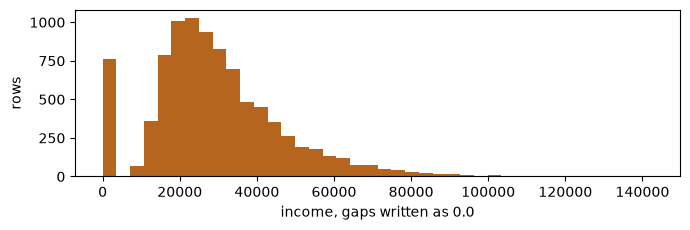

In [ ]:
#@title Figure: income with the gaps written as 0.0  { display-mode: "form" }
inc = column("income")
as_zero = np.where(np.isnan(inc), 0.0, inc)
plt.figure(figsize=(7, 2.4))
plt.hist(as_zero, bins=40, color="#b5651d")
plt.xlabel("income, gaps written as 0.0")
plt.ylabel("rows")
plt.tight_layout()
plt.show()

## 03 Counting rows and categories

Before we compute any statistic, we count the rows of the table and see how they are spread across the categories of each categorical column. We also count the missing values in each numeric column. These counts give the number of values that each later statistic is computed from.

In [ ]:
plan = np.array([r["plan"] for r in records])

print('(plan == "premium").sum():', (plan == "premium").sum())
print("np.unique(plan)          :", np.unique(plan))

names, counts = np.unique(plan, return_counts=True)
for name, n in zip(names, counts):
    print(f"   {name:<10} {n}")

(plan == "premium").sum(): 1828
np.unique(plan)          : ['basic' 'legacy' 'premium' 'standard']
   basic      3103
   legacy     1250
   premium    1828
   standard   2819


### Categories with no rows

`np.unique` returns the categories in alphabetical order and reports only the categories that
occur. If a category is defined by the domain and happens to be absent, it is missing from the output. Counting
against a fixed list avoids that and makes the zero visible.

In [ ]:
col = np.array([r["plan"] for r in records])
counts = {name: int((col == name).sum()) for name in CATEGORIES["plan"]}
print(counts)
print("sum:", sum(counts.values()), "of", len(records), "rows")

{'basic': 3103, 'standard': 2819, 'premium': 1828, 'legacy': 1250}
sum: 9000 of 9000 rows


Checking that the counts add up to the number of rows detects a misspelled category, a trailing space in the file and a category that was not in the list.

**Try it.** Change `"plan"` above to `"region"` or `"channel"` and run it again.

### Missing values per column

The same count works for the gaps.

**Try it.** Count the missing values in each of the four numeric columns.

In [ ]:
for name in ["age", "income", "tenure_months", "score"]:
    v = column(name)
    print(f"{name:<14} missing {int(np.isnan(v).sum()):>4}   present {int((~np.isnan(v)).sum()):>5}")

age            missing  564   present  8436
income         missing  763   present  8237
tenure_months  missing    0   present  9000
score          missing  373   present  8627


One column has no gaps. Its count is 0.

## 04 Summary statistics

We describe a numeric column by five statistics: the mean and the median for its centre, the standard deviation for its spread, and the minimum and the maximum for its extremes. We compute them for `score` and for every column of the table. We also add one impossible score to see how far each of them moves.

In [ ]:
score = column("score")
s = score[~np.isnan(score)]          # drop the gaps once, reuse below

print("n       ", len(s))
print("mean    ", round(float(s.mean()), 2))
print("median  ", round(float(np.median(s)), 2))
print("std     ", round(float(s.std()), 2))
print("min, max", float(s.min()), float(s.max()))
print("quartiles", np.quantile(s, [0.25, 0.5, 0.75]))

n        8627
mean     58.85
median   59.1
std      13.16
min, max 8.8 100.0
quartiles [50.1 59.1 67.6]


### Reductions with axis=0

With the table in one array a reduction takes `axis=0` and returns one value per column. The axis named is the one that disappears. A `(9000, 7)` table therefore reduces to `(7,)`.

In [ ]:
print("plain mean  ", table.mean(axis=0))          # NaN for the three numeric columns with gaps
print("nanmean     ", np.nanmean(table, axis=0)[:4])
print("nanmin      ", np.nanmin(table, axis=0)[:4])
print("nanmax      ", np.nanmax(table, axis=0)[:4])
print("result shape", np.nanmean(table, axis=0).shape)

plain mean   [       nan        nan 26.727777         nan  2.1654444  1.1361111
  1.1295556]
nanmean      [4.3119015e+01 3.1837699e+04 2.6727777e+01 5.8849316e+01]
nanmin       [  18.   6138.67    0.      8.8 ]
nanmax       [8.4000000e+01 1.4261066e+05 1.4500000e+02 1.0000000e+02]
result shape (7,)


Pairing the result with the column names labels each value. `map(float, ...)` is there because NumPy
prints its own scalar types in full, as `np.float32(43.12)` rather than `43.12`.

In [ ]:
for name, value in zip(COLUMNS, map(float, np.nanmean(table, axis=0))):
    print(f"   {name:<14} {value:>10.2f}")

   age                 43.12
   income           31837.70
   tenure_months       26.73
   score               58.85
   region               2.17
   plan                 1.14
   channel              1.13


Counting works the same way. `axis` sets what is being counted.

In [ ]:
missing = np.isnan(table)

print("per column       ", np.count_nonzero(missing, axis=0))
print("rows with a gap  ", np.count_nonzero(np.any(missing, axis=1)))
print("columns with gaps", np.where(np.any(missing, axis=0))[0],
      [COLUMNS[i] for i in np.where(np.any(missing, axis=0))[0]])

per column        [564 763   0 373   0   0   0]
rows with a gap   1597
columns with gaps [0 1 3] ['age', 'income', 'score']


The middle line counts the rows with a gap somewhere, 1597 of 9000. Dropping every incomplete row therefore keeps only 7403.

### Sorting a column with gaps

`np.sort` returns a sorted copy. `np.argsort` returns the order rather than the values. On a column with gaps both put the NaNs at the end. The first positions then hold the smallest values. The last positions hold NaN rather than the largest values.

In [ ]:
inc = table[:, 1]                # income, 763 of the 9000 missing

print("three smallest", np.sort(inc)[:3])
print("three largest?", np.sort(inc)[-3:], "  <- not what was asked")

three smallest [6138.67 7221.34 7492.29]
three largest? [nan nan nan]   <- not what was asked


The gaps can be dropped before sorting, or moved to the front with
`-np.inf`, negative infinity, a float that compares below every real number.

In [ ]:
present = inc[~np.isnan(inc)]
print("dropped then sorted", np.sort(present)[-3:])

filled = inc.copy()
filled[np.isnan(filled)] = -np.inf
print("-inf then sorted   ", np.sort(filled)[-3:])

dropped then sorted [132465.06 133638.58 142610.66]
-inf then sorted    [132465.06 133638.58 142610.66]


`np.argsort` returns row numbers. One column can therefore be ordered and another read off in the same order. Dropping
the gaps breaks that, because every index after a dropped row shifts.

In [ ]:
order = np.argsort(inc)
n_missing = int(np.isnan(inc).sum())
top3 = order[-n_missing - 3 : -n_missing]

print("naive     ", inc[order[-3:]])
print("corrected ", inc[top3])
print("their ages", table[top3, 0])

carried = np.flatnonzero(~np.isnan(inc))[np.argsort(present)][-3:]
print("same rows via carried indices:", np.array_equal(carried, top3))

naive      [nan nan nan]
corrected  [132465.06 133638.58 142610.66]
their ages [59. 67. 61.]
same rows via carried indices: True


`np.sort` also takes an axis. On a table it sorts every column independently. Its rows are no longer customers. The smallest age and the smallest income almost certainly belong to two different people.

In [ ]:
print(np.sort(table, axis=0)[:3])

[[  18.   6138.67    0.      8.8     0.      0.      0.  ]
 [  18.   7221.34    0.     15.3     0.      0.      0.  ]
 [  18.   7492.29    0.     16.5     0.      0.      0.  ]]


### Quantiles

`np.quantile(s, q)` returns the value below which the fraction `q` of the data falls. The three at 0.25, 0.5 and 0.75 are the quartiles. A quarter of the scores sit below 50.1, half below 59.1 and three quarters below 67.6. The middle one is the median by definition. Where the fraction does not land on an observation, NumPy interpolates between the two values either side. A quartile is therefore usually not a value present in the data. `np.percentile` is the same thing on a 0
to 100 scale.

The distance between the outer two is the interquartile range, 17.5 here. It is the spread of the middle half, computed without reference to the mean.


In [ ]:
q = np.quantile(s, [0.25, 0.5, 0.75])
print("quartiles         ", q)
print("median matches q2 ", float(np.median(s)) == float(q[1]))
print("interquartile range", round(float(q[2] - q[0]), 1))
print("fraction below q1 ", round(float((s < q[0]).mean()), 3))


quartiles          [50.1 59.1 67.6]
median matches q2  True
interquartile range 17.5
fraction below q1  0.249


### Mean and median

On a symmetric column the mean and the median nearly agree. On a skewed one they differ. The difference between them shows the direction of the skew.

In [ ]:
inc = income[~np.isnan(income)]
print("income mean  ", round(float(inc.mean()), 2))
print("income median", round(float(np.median(inc)), 2))
print("difference   ", round(float(inc.mean() - np.median(inc)), 2))

income mean   31837.68
income median 28210.26
difference    3627.42


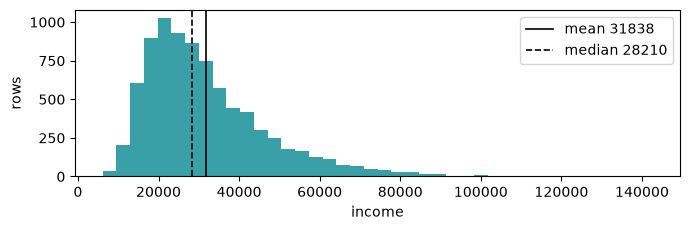

In [ ]:
#@title Figure: mean and median of income  { display-mode: "form" }
income_all = column("income")
present = income_all[~np.isnan(income_all)]
plt.figure(figsize=(7, 2.4))
plt.hist(present, bins=40, color="#39a0a8")
plt.axvline(present.mean(), color="black", linewidth=1.2, label=f"mean {present.mean():.0f}")
plt.axvline(np.median(present), color="black", linestyle="--", linewidth=1.2,
            label=f"median {np.median(present):.0f}")
plt.xlabel("income")
plt.ylabel("rows")
plt.legend()
plt.tight_layout()
plt.show()

A mean above the median indicates a long right tail.

### ddof

`np.std` divides by `n`. Many statistics texts and `statistics.stdev` divide by `n - 1`. This corrects a bias that arises when the data is a sample from a larger population. The deviations are measured from the sample mean. The sample mean sits exactly where it makes their sum of squares as small as possible. Dividing by `n` therefore gives a variance that is on average smaller than the population variance by a factor of `(n - 1) / n`. NumPy exposes the choice as `ddof`, the delta degrees of
freedom, and defaults it to 0.

Which one to use follows from what the rows are. The spread of *these* 8627 scores is a property of the rows in hand. `ddof=0` computes it exactly. NumPy's default is therefore the right one here. `ddof=1` is for rows that are a sample of a larger population that cannot be measured. The result is then an estimate of that population's spread.

The difference between the two shrinks as the number of values grows. Here it is in the fourth decimal place. At twenty values it is 2.6 per cent. At five it is 12 per cent.

In [ ]:
print("ddof=0 (divides by n)    ", round(float(s.std()), 4))
print("ddof=1 (divides by n - 1)", round(float(s.std(ddof=1)), 4))

small = s[:20]
print()
print("on 20 values: ddof=0", round(float(small.std()), 3),
      " ddof=1", round(float(small.std(ddof=1)), 3))

ddof=0 (divides by n)     13.1642
ddof=1 (divides by n - 1) 13.1649

on 20 values: ddof=0 13.535  ddof=1 13.887


### Robustness to one extreme value

One impossible value, such as a score typed with an extra digit, moves the five statistics by very
different amounts.

In [ ]:
t = np.append(s, 10_000.0)           # one impossible score

print("mean   moves by", round(float(t.mean() - s.mean()), 2))
print("median moves by", round(float(np.median(t) - np.median(s)), 2))
print("max    moves by", round(float(t.max() - s.max()), 2))
print("std    moves by", round(float(t.std() - s.std()), 2))

mean   moves by 1.15
median moves by 0.0
max    moves by 9900.0
std    moves by 94.66


The median and the quartiles are robust. They depend on the order of the values, not on their size. The mean, the standard deviation and the extremes are not robust. An impossible value usually shows up in `min` or `max`. Printing those two is a quick check on a new column.

## 05 Pairwise and listwise deletion

When we leave a missing value out of a calculation, we can drop the whole row it belongs to or drop only that one value. The two choices give different numbers. We compute the mean score both ways and look at which customers each of the two results describes.

**Listwise deletion**, or complete-case analysis, drops every row with a gap in any column.
**Pairwise deletion**, or available-case analysis, keeps for each statistic every row where the
columns that statistic needs are present.

In [ ]:
age, score_c = column("age"), column("score")
inc_c, ten_c = column("income"), column("tenure_months")

complete = ~np.isnan(age) & ~np.isnan(inc_c) & ~np.isnan(score_c) & ~np.isnan(ten_c)

print("rows total           ", len(records))
print("rows fully complete  ", int(complete.sum()))
print("lost to listwise     ", len(records) - int(complete.sum()),
      f"({(len(records) - int(complete.sum())) / len(records):.1%})")
print()
print("mean score, pairwise :", round(float(score_c[~np.isnan(score_c)].mean()), 4),
      f"over {int((~np.isnan(score_c)).sum())} rows")
print("mean score, listwise :", round(float(score_c[complete].mean()), 4),
      f"over {int(complete.sum())} rows")

rows total            9000
rows fully complete   7403
lost to listwise      1597 (17.7%)

mean score, pairwise : 58.8494 over 8627 rows
mean score, listwise : 58.8511 over 7403 rows


The first is the mean of every score that is present. The second is the mean score among customers whose record is complete in all four columns. Those customers are a different population from the customers with a recorded score.

### Functions that ignore NaNs

NumPy has a parallel set of reductions that skip NaN instead of propagating it. Each of them does pairwise deletion in one call.

In [ ]:
print("np.nanmean  ", round(float(np.nanmean(score_c)), 4))
print("by hand     ", round(float(score_c[~np.isnan(score_c)].mean()), 4))
print("identical   ", np.nanmean(score_c) == score_c[~np.isnan(score_c)].mean())
print()
for f in (np.nansum, np.nanmean, np.nanmedian, np.nanstd, np.nanmin, np.nanmax):
    print(f"{f.__name__:<12}", round(float(f(score_c)), 3))

np.nanmean   58.8494
by hand      58.8494
identical    True

nansum       507693.5
nanmean      58.849
nanmedian    59.1
nanstd       13.164
nanmin       8.8
nanmax       100.0


## 06 Grouped summaries

A grouped summary is a statistic that we compute once for each category of another column, such as the mean score in each region.

Over the whole column the mean score is `58.85`. Region by region, the six means run from 51 to 67.

Each of those six is an ordinary mean over a subset of the rows. A boolean mask selects the subset. `region == "Upland"` is True on the Upland rows. `~np.isnan(score_c)` is True on the rows that have a score. `&` keeps the rows where both hold.

In [ ]:
region = np.array([r["region"] for r in records])

for name in CATEGORIES["region"]:
    sel = (region == name) & ~np.isnan(score_c)
    print(f"{name:<10} n={int(sel.sum()):>5}  mean score {float(score_c[sel].mean()):6.2f}")

North      n= 1833  mean score  51.28
Harbour    n= 1578  mean score  60.76
Midland    n= 1738  mean score  58.55
Eastfield  n= 1200  mean score  65.20
Southgate  n= 1347  mean score  55.65
Upland     n=  931  mean score  67.49


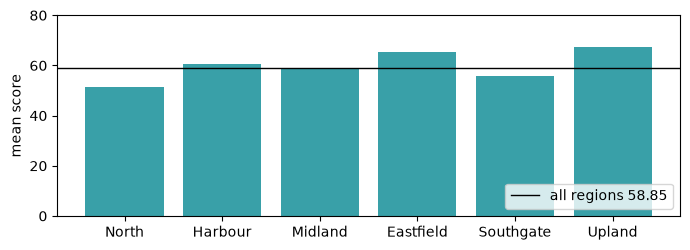

In [ ]:
#@title Figure: mean score per region  { display-mode: "form" }
score = column("score")
region = np.array([r["region"] for r in records])
names = CATEGORIES["region"]
means = [score[(region == n) & ~np.isnan(score)].mean() for n in names]
plt.figure(figsize=(7, 2.6))
plt.bar(range(len(names)), means, color="#39a0a8")
plt.axhline(np.nanmean(score), color="black", linewidth=1,
            label=f"all regions {np.nanmean(score):.2f}")
plt.xticks(range(len(names)), names)
plt.ylabel("mean score")
plt.ylim(0, 80)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

The loop prints the group size next to each mean. A mean over 931 rows is less precise than one over 1833. An empty group gives NaN.

**Try it.** Swap the numeric column for `income` and the categorical one for `plan`.

### Deletion inside a group

The mask above tests the column being averaged. Testing completeness across all columns instead changes every group. It changes them unevenly, because the gaps are not spread evenly across regions. As for the whole column, the gaps are skipped only in the column the statistic is about.

In [ ]:
complete = (~np.isnan(column("age")) & ~np.isnan(column("income"))
            & ~np.isnan(score_c) & ~np.isnan(column("tenure_months")))

pairwise = (region == "Upland") & ~np.isnan(score_c)
listwise = (region == "Upland") & complete

print(f"pairwise {score_c[pairwise].mean():.2f} over {int(pairwise.sum())} rows")
print(f"listwise {score_c[listwise].mean():.2f} over {int(listwise.sum())} rows")

pairwise 67.49 over 931 rows
listwise 67.66 over 801 rows


## 07 Bar charts

A bar chart shows one count per category as the height of a bar. We use it for the rows per plan and for the missing values per numeric column. We draw the bars with `plt.bar` and label them with `plt.xticks` and `plt.ylabel`.

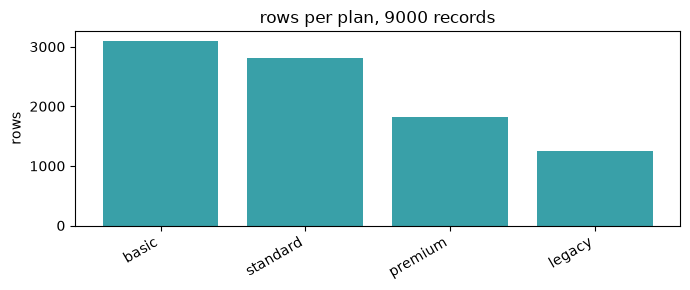

In [ ]:
names = CATEGORIES["plan"]
values = [int((plan == name).sum()) for name in names]

plt.figure(figsize=(7, 3))
plt.bar(range(len(names)), values, color="#39a0a8")
plt.xticks(range(len(names)), names, rotation=30, ha="right")
plt.ylabel("rows")
plt.title(f"rows per plan, {len(records)} records")
plt.tight_layout()
plt.show()

`plt.bar` places bars at the x positions it is given. The positions are therefore `range(len(names))`. `plt.xticks` attaches the names afterwards. Rotating long labels and anchoring them at
their right end keeps them from overlapping. `plt.tight_layout()` resizes the axes so the rotated
labels sit inside the figure.

### Axis labels and counts

A chart needs a labelled y axis, every category including the empty ones, and the number of rows it
was drawn from.

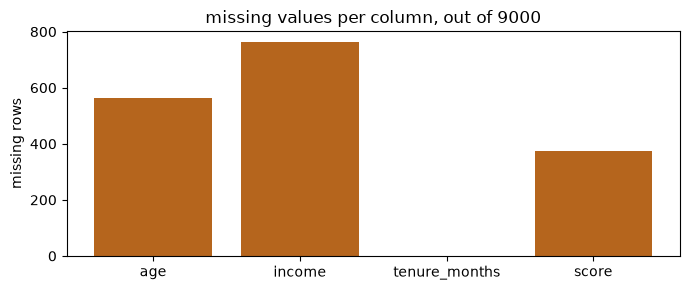

In [ ]:
# Missing values per column, as a chart rather than a table.
cols = ["age", "income", "tenure_months", "score"]
miss = [int(np.isnan(column(c)).sum()) for c in cols]

plt.figure(figsize=(7, 3))
plt.bar(range(len(cols)), miss, color="#b5651d")
plt.xticks(range(len(cols)), cols)
plt.ylabel("missing rows")
plt.title(f"missing values per column, out of {len(records)}")
plt.tight_layout()
plt.show()

The column with no gaps gets a bar of height zero. The bar is visible because the column is in the list.

## 08 Histograms

A histogram divides the range of a column into intervals, the bins, and counts how many values fall into each. It reduces thousands of values to one count per bin. We compute the counts for the 8627 present scores with `np.histogram` and draw them with `plt.hist`.

In [ ]:
counts, edges = np.histogram(s, bins=20, range=(0, 100))

print("counts.shape", counts.shape)     # one count per bin
print("edges.shape ", edges.shape)      # one more edge than bin
print("edges[:4]   ", edges[:4])        # width 5.0 each
print("counts.sum()", counts.sum())     # every value is in a bin

counts.shape (20,)
edges.shape  (21,)
edges[:4]    [ 0.  5. 10. 15.]
counts.sum() 8627


The two returned arrays differ in length by one, because `n` intervals need `n + 1` boundaries. Bin `i` covers `edges[i]` up to `edges[i+1]`, with the left edge included and the right edge excluded. The last bin includes both edges, so that the maximum value is counted.

If `counts.sum()` is smaller than the number of values, some values fell outside `range` and were left out without a warning.

### plt.hist

`plt.hist` computes and draws in one call, taking the same `bins` and `range` arguments. It leaves NaN out without a warning. The code takes the gaps out first. `len(s)` is then the number of values drawn.

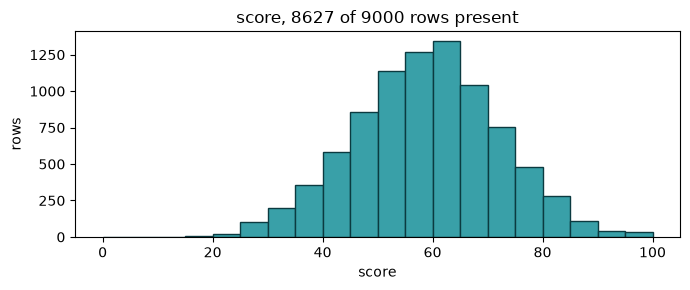

In [ ]:
plt.figure(figsize=(7, 3))
plt.hist(s, bins=20, range=(0, 100), color="#39a0a8", edgecolor="#0b3a40")
plt.xlabel("score")
plt.ylabel("rows")
plt.title(f"score, {len(s)} of 9000 rows present")
plt.tight_layout()
plt.show()

Nothing in a histogram shows that 373 rows were left out. The title therefore states the number of present values.

**Try it.** Draw the same histogram with `bins=10` and with `bins=50`.

### density=True

In [ ]:
c, e = np.histogram(s, bins=20, range=(0, 100), density=True)

print("c.sum()               ", round(float(c.sum()), 4))                # not 1
print("(c * np.diff(e)).sum()", round(float((c * np.diff(e)).sum()), 4))  # the area is 1

c.sum()                0.2
(c * np.diff(e)).sum() 1.0


`np.diff` gives the differences between consecutive values. `np.diff(e)` is therefore the width of each bin. The product above is height times width, bin by bin.

`density=True` scales the counts so the total area is one, not so the values sum to one. Each returned value is the share of the rows in its bin divided by the bin width. With bins 5 wide, the values therefore sum to 1 / 5 = 0.2. The scaling makes histograms with different bin widths comparable. The numbers on the y axis are then no longer rows.

## 09 Bin count and range

The number of bins and the range they cover both change what a histogram shows. The data fixes neither of them. We therefore choose both ourselves. We look at what each choice does to the histogram of `score` and at the bins NumPy uses when we leave the choice to it.

### Bin count

With few bins the histogram shows only the coarsest shape. With many bins, each bar holds few values. Neighbouring bars then differ by chance. The table bins the same 8627 scores three ways:

In [ ]:
for n in [5, 20, 60]:
    counts, _ = np.histogram(s, bins=n, range=(0, 100))
    print(f"{n:>3} bins  width {100 / n:5.2f}  tallest {counts.max():>5}  "
          f"empty {int((counts == 0).sum())}")

print('bins="auto":', len(np.histogram_bin_edges(s, bins="auto")) - 1, "bins")

  5 bins  width 20.00  tallest  3852  empty 0
 20 bins  width  5.00  tallest  1343  empty 2
 60 bins  width  1.67  tallest   464  empty 8
bins="auto": 54 bins


| bins | width | tallest bin | empty bins | appearance |
|---|---|---|---|---|
| 5 | 20.0 | 3852 | 0 | That the middle is fuller than the ends, and nothing else |
| 20 | 5.0 | 1343 | 2 | A single rounded peak with thin tails |
| 60 | 1.67 | 464 | 8 | The same peak, with sampling noise on top |

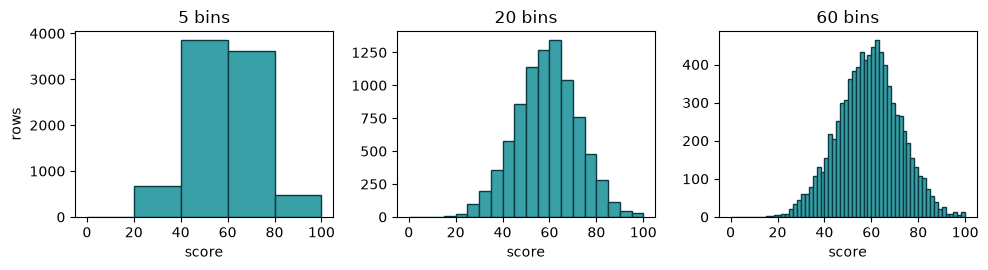

In [ ]:
#@title Figure: the same scores with 5, 20 and 60 bins  { display-mode: "form" }
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, n in zip(axes, [5, 20, 60]):
    ax.hist(s, bins=n, range=(0, 100), color="#39a0a8", edgecolor="#0b3a40")
    ax.set_title(f"{n} bins")
    ax.set_xlabel("score")
axes[0].set_ylabel("rows")
fig.tight_layout()
plt.show()

NumPy can choose the count. `bins="auto"` takes the smaller bin width of two standard rules, Sturges' and Freedman-Diaconis'. For these scores it gives 54 bins. A feature that appears at one bin count and not at the next is a property of the binning rather than of the data.

### Range

Without `range`, NumPy uses the smallest and largest value present. The bin edges then depend on the data rather than on the quantity. They also stop being round numbers.

In [ ]:
print(np.histogram(s, bins=20)[1][:3])                   # from the data
print(np.histogram(s, bins=20, range=(0, 100))[1][:3])   # from the definition

[ 8.8  13.36 17.92]
[ 0.  5. 10.]


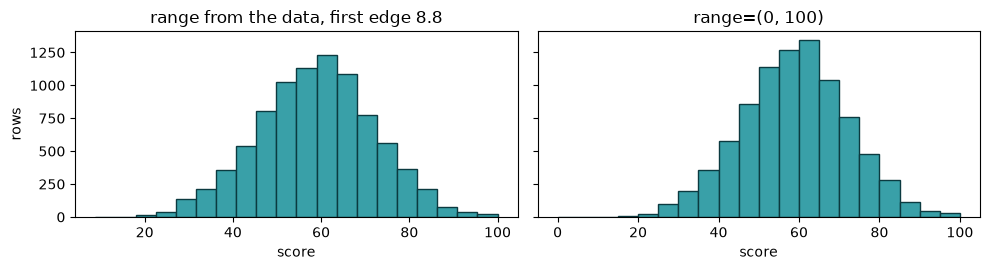

In [ ]:
#@title Figure: bin edges from the data and from the definition  { display-mode: "form" }
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
axes[0].hist(s, bins=20, color="#39a0a8", edgecolor="#0b3a40")
axes[0].set_title(f"range from the data, first edge {s.min():.1f}")
axes[1].hist(s, bins=20, range=(0, 100), color="#39a0a8", edgecolor="#0b3a40")
axes[1].set_title("range=(0, 100)")
for ax in axes:
    ax.set_xlabel("score")
axes[0].set_ylabel("rows")
fig.tight_layout()
plt.show()

Score is defined on 0 to 100. That range is used even though no customer scored below 8.8. Using that range has two effects on what the figure can be compared with:

- **Two histograms become comparable.** Binned over their own observed ranges, the scores of two regions get different bin edges and cannot be compared bin by bin.
- **Empty bins show where there are no values.** The first bin is empty because no customer scores below 5. An axis starting at 8.8 leaves that bin out.

Where the quantity has no defined range, as `income` does not, the observed range is the only option, either whole or with the tail cut off.

### Empty bins in the tail

A bell-shaped column binned finely enough has empty bins in its tails, where no value happened to fall. They are part of the data at that bin width.

## 10 Distribution shapes

Most histograms have one of a few recognisable shapes. Which statistics describe a column well depends on its shape. We match two of the register's columns to these shapes and draw the one with a long tail on a logarithmic axis.

| Shape | Appearance | Consequence |
|---|---|---|
| Symmetric, one peak | Mean and median nearly equal | The mean and the standard deviation describe it. |
| Right-skewed | Long tail to the right, mean above median | The median describes it better than the mean. A log scale makes the tail readable. |
| Two peaks | Two separate humps | Two populations are mixed. Another column may separate them. |
| A spike at one value | One bin far above its neighbours | The spike is usually a default, a cap or missing values written as a number. |
| Values at the edge | The first or last bin is tall | The quantity is clipped. The extremes are not real extremes. |

The register's `score` is the first shape: one rounded peak near 59, thin on both sides, mean 58.85 against median 59.10. Its `income` is the second: mean 31838 against median 28210, a long right tail, and a histogram in which most of the width is nearly empty.

In [ ]:
print(f"score   mean {np.nanmean(score):8.2f}   median {np.nanmedian(score):8.2f}")
print(f"income  mean {np.nanmean(income):8.0f}   median {np.nanmedian(income):8.0f}")

score   mean    58.85   median    59.10
income  mean    31838   median    28210


### Log scale

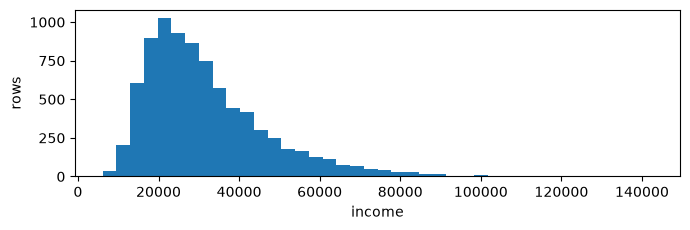

In [ ]:
plt.figure(figsize=(7, 2.4))
plt.hist(inc, bins=40)                  # 40 bins of equal width, about 3410 each
plt.xlabel("income")
plt.ylabel("rows")
plt.tight_layout()
plt.show()

On an ordinary axis the histogram is a peak near 20000 followed by a tail. The tallest bar holds 1027 rows. The right half of the figure, 20 of the 40 bars, holds 167 of the 8237 incomes, 2 per cent.

In [ ]:
counts, edges = np.histogram(inc, bins=40)
print("tallest bar:", counts.max(), "rows, from", round(float(edges[counts.argmax()])))
print("right half of the bars:", counts[20:].sum(), "of", counts.sum(), "incomes")
print("largest / smallest income:", round(float(inc.max() / inc.min()), 1))

tallest bar: 1027 rows, from 19786
right half of the bars: 167 of 8237 incomes
largest / smallest income: 23.2


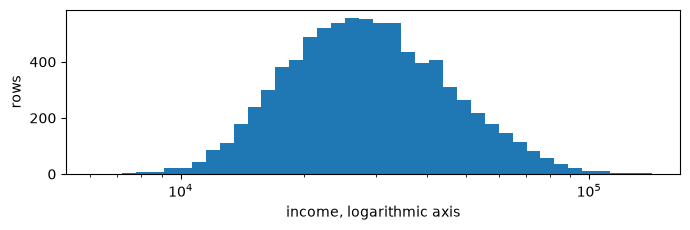

In [ ]:
edges = np.geomspace(inc.min(), inc.max(), 41)   # 41 edges, each 1.082 times the last
plt.figure(figsize=(7, 2.4))
plt.hist(inc, bins=edges)
plt.xscale("log")
plt.xlabel("income, logarithmic axis")
plt.ylabel("rows")
plt.tight_layout()
plt.show()

A logarithmic axis spaces the values by ratio instead of by difference. The distance from 10000 to 20000 is the same as the distance from 50000 to 100000. Income's largest value is 23 times its smallest. On this axis the whole range is readable. `np.geomspace(start, stop, n)` returns `n` values with a constant ratio between neighbours. It is the logarithmic counterpart of `np.linspace`. The 40 bins therefore come out equally wide on the logarithmic axis. On the same axis, the equal-width bins of the first figure would be wide on the left and narrow on the right. The axis label states that the axis is logarithmic, because distances on it are ratios rather than differences.

### Spikes at one value

A tall bar at exactly zero in a column of amounts, or at exactly the same value in several columns, is often missing data filled in with a fixed value before the file was written.

## 11 Scatter plots

A scatter plot draws every row on its own, as one point at the coordinates of two columns. A histogram shows only how many rows fall into each bin. We plot `tenure_months` against `age` for the 8436 customers who have both values.

8436 of 9000 rows have both


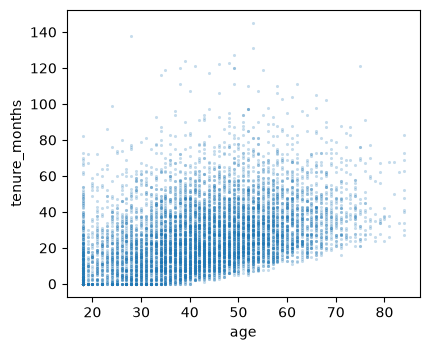

In [ ]:
k = ~np.isnan(age) & ~np.isnan(tenure)   # pairwise complete: both present
print(k.sum(), "of 9000 rows have both")

plt.figure(figsize=(4.4, 3.6))
plt.scatter(age[k], tenure[k], s=5, alpha=0.25, linewidths=0)
plt.xlabel("age")
plt.ylabel("tenure_months")
plt.tight_layout()
plt.show()

Both arrays passed to `scatter` must have the same length. The same mask has to select the rows of both, or the points pair up the wrong rows. One combined mask is therefore applied to both columns.

### Overplotting

8436 points in a small figure overlap into a solid area in which dense and sparse regions look the same. Three arguments reduce the overlap:

- `s=5` shrinks the markers. Fewer of them then touch.
- `alpha=0.25` makes them translucent. Four overlapping points are then visibly darker than one. The dense core of the cloud becomes readable.
- `linewidths=0` removes the marker outline. At this size the outline makes up most of the marker.

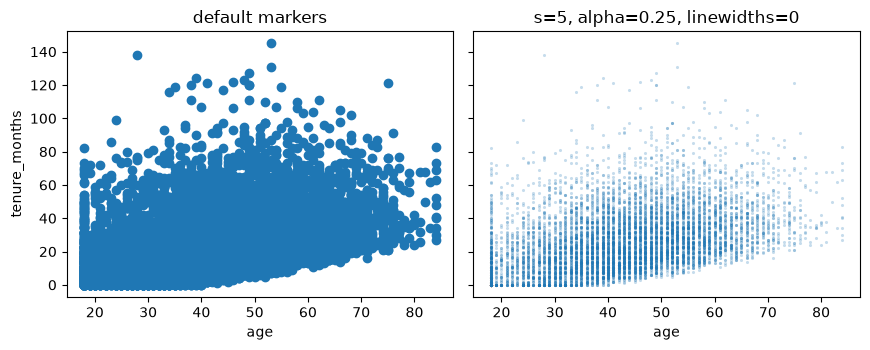

In [ ]:
#@title Figure: default markers against s=5, alpha=0.25, linewidths=0  { display-mode: "form" }
k = ~np.isnan(age) & ~np.isnan(tenure)
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.6), sharex=True, sharey=True)
axes[0].scatter(age[k], tenure[k])
axes[0].set_title("default markers")
axes[1].scatter(age[k], tenure[k], s=5, alpha=0.25, linewidths=0)
axes[1].set_title("s=5, alpha=0.25, linewidths=0")
for ax in axes:
    ax.set_xlabel("age")
axes[0].set_ylabel("tenure_months")
fig.tight_layout()
plt.show()

For many more points, a joint histogram shows the density without drawing every point. It counts the points in each cell of a grid.

### Direction, shape, spread, exceptions

A scatter plot is read for four things, in this order: the **direction** (whether y rises with x), the **shape** (a straight band, a curve, a fan), the **spread** (tight or diffuse), and the **exceptions** (points far from the rest). Tenure rises with age in the register. The median tenure is 12 months for customers aged 18 to 27 and 38 months for those aged 78 and over. The band is wide and straight. Along its lower edge 317 customers sit at exactly 0 months, 294 of them younger than 35. Nine points lie far above the band, at more than 120 months.

In [ ]:
k = ~np.isnan(age) & ~np.isnan(tenure)
print("median tenure, aged 18 to 27   :", np.median(tenure[k & (age >= 18) & (age <= 27)]))
print("median tenure, aged 78 and over:", np.median(tenure[k & (age >= 78)]))
zero = k & (tenure == 0)
print("tenure exactly 0:", zero.sum(), "  of them younger than 35:", (zero & (age < 35)).sum())
print("tenure above 120:", (k & (tenure > 120)).sum())

median tenure, aged 18 to 27   : 12.0
median tenure, aged 78 and over: 38.0
tenure exactly 0: 317   of them younger than 35: 294
tenure above 120: 9


## 12 Correlation

The correlation coefficient measures how closely two columns follow a straight line. We compute it with `np.corrcoef`, NumPy's function for the Pearson product-moment correlation coefficient. "Correlation" means this coefficient unless another one is named.

In [ ]:
k = ~np.isnan(age) & ~np.isnan(tenure)
print(np.corrcoef(age[k], tenure[k]))                     # (2, 2) matrix, not one number
print(round(float(np.corrcoef(age[k], tenure[k])[0, 1]), 3))   # the coefficient

[[1.         0.39050962]
 [0.39050962 1.        ]]
0.391


`np.corrcoef` returns the matrix of every pair. Two inputs give a 2 by 2 matrix with ones on the diagonal. The coefficient of the pair is off the diagonal. The coefficient runs from -1 to +1: +1 is a perfectly rising straight line, -1 a perfectly falling one, 0 no straight-line relationship at all.

The table gives the correlation of the six numeric pairs in the register, each over the rows where both columns are present:

In [ ]:
cols = {"age": age, "income": income, "tenure_months": tenure, "score": score}
pairs = [("age", "tenure_months"), ("age", "income"), ("income", "score"),
         ("income", "tenure_months"), ("tenure_months", "score"), ("age", "score")]
for p, q in pairs:
    k = ~np.isnan(cols[p]) & ~np.isnan(cols[q])
    r = np.corrcoef(cols[p][k], cols[q][k])[0, 1]
    print(f"{p + ', ' + q:<24} r = {r:+.3f}   rows {k.sum()}")

age, tenure_months       r = +0.391   rows 8436
age, income              r = +0.322   rows 7720
income, score            r = +0.227   rows 7895
income, tenure_months    r = +0.123   rows 8237
tenure_months, score     r = +0.103   rows 8627
age, score               r = +0.058   rows 8089


| pair | r | rows | reading |
|---|---|---|---|
| `age`, `tenure_months` | +0.391 | 8436 | Older customers have longer tenure |
| `age`, `income` | +0.322 | 7720 | Income rises with age |
| `income`, `score` | +0.227 | 7895 | A weak rise |
| `income`, `tenure_months` | +0.123 | 8237 | Very weak |
| `tenure_months`, `score` | +0.103 | 8627 | Very weak |
| `age`, `score` | +0.058 | 8089 | None |

Each pair has its own row count, because each pair loses a different set of rows to missing values. Computed over only the rows complete in all four columns, the six coefficients would describe a different population, as listwise deletion does for a mean.

### Nonlinear relationships

An exact relationship can still give a correlation of zero:

In [ ]:
x = np.linspace(-3, 3, 400)
y = x ** 2                              # y is completely determined by x
print(f"{np.corrcoef(x, y)[0, 1]:.6f}")

-0.000000


Every value of y is fixed by x. The coefficient is still zero. As x rises, y first falls and then rises. The two halves cancel. A correlation near zero rules out only a straight-line relationship. A scatter plot shows whether another one exists.

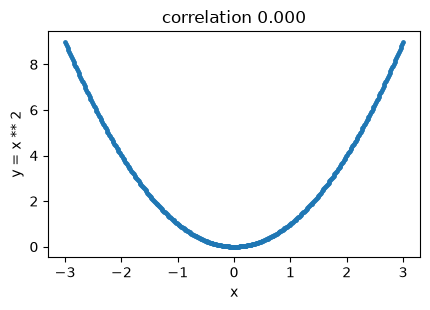

In [ ]:
#@title Figure: the 400 points of y = x ** 2  { display-mode: "form" }
r = np.corrcoef(x, y)[0, 1]
plt.figure(figsize=(4.4, 3.2))
plt.scatter(x, y, s=6)
plt.xlabel("x")
plt.ylabel("y = x ** 2")
plt.title(f"correlation {round(r, 3) + 0.0:.3f}")
plt.tight_layout()
plt.show()

### Correlation and causation

A correlation coefficient does not indicate which column causes which, or whether either does. Two columns both driven by a third correlate with each other. Nothing in the number marks that case.

### Influence of a single point

In [ ]:
rng = np.random.default_rng(0)          # a random generator with a fixed seed
a = rng.normal(0, 1, 300)               # 300 values, mean 0, standard deviation 1
b = 0.6 * a + rng.normal(0, 0.8, 300)   # 0.6 * a plus noise
print(f"{np.corrcoef(a, b)[0, 1]:+.3f}")

a2 = np.append(a, 20.0)                 # one point, far out, in the opposite corner
b2 = np.append(b, -20.0)
print(f"{np.corrcoef(a2, b2)[0, 1]:+.3f}")   # sign reversed by one row in 301

+0.637
-0.286


`np.random.default_rng(0)` creates a random number generator seeded with 0. The same values therefore come out on every run. `rng.normal(mean, std, n)` draws `n` values from a normal distribution. The coefficient is built from products of distances from the mean. A point far from both means therefore dominates the sum. The scatter plot shows that point.

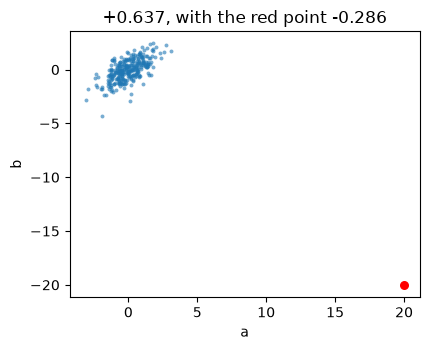

In [ ]:
#@title Figure: one point far from both means  { display-mode: "form" }
plt.figure(figsize=(4.4, 3.6))
plt.scatter(a, b, s=8, alpha=0.6, linewidths=0)
plt.scatter([20.0], [-20.0], s=30, color="red")
plt.xlabel("a")
plt.ylabel("b")
plt.title(f"{np.corrcoef(a, b)[0, 1]:+.3f}, with the red point {np.corrcoef(a2, b2)[0, 1]:+.3f}")
plt.tight_layout()
plt.show()

**Try it.** Compute the correlation of `score` with `churn` over the rows where `score` is present.

## 13 Joint histograms

A joint histogram divides the plane of two columns, one on each axis, into a grid of cells and counts the rows that fall inside each cell. NumPy's documentation calls it a bi-dimensional histogram. We bin `score` and `tenure_months` jointly into a 5 by 5 grid with `np.histogram2d` and draw the counts with `plt.pcolormesh`.

In [ ]:
k = ~np.isnan(score) & ~np.isnan(tenure)
J, xe, ye = np.histogram2d(score[k], tenure[k], bins=[5, 5],
                           range=[[0, 100], [0, 180]])

print("J.shape", J.shape, J.dtype)      # counts, as float64
print("J.sum()", J.sum())               # every pair is in a cell
print("xe", xe)                         # score edges
print("ye", ye)                         # tenure edges

J.shape (5, 5) float64
J.sum() 8627.0
xe [  0.  20.  40.  60.  80. 100.]
ye [  0.  36.  72. 108. 144. 180.]


`bins` and `range` take one entry per axis. The counts come back as **float64**. A count therefore prints as `2865.0`. The first argument indexes the *first* axis of the result. `J[i, j]` is therefore the number of rows whose score is in band `i` and whose tenure is in band `j`.

In [ ]:
print(J.astype(int))                    # rows: score bands 0-20 to 80-100. Columns: tenure bands

print("J[0]   ", J[0])                  # the lowest score band, across tenure
print("J[:, 0]", J[:, 0])               # the lowest tenure band, across score
print("empty cells:", int((J == 0).sum()), "of 25")

[[   7    2    0    0    0]
 [ 530  139    8    1    0]
 [2865  914   66    6    1]
 [2570  948   89   12    0]
 [ 297  152   19    1    0]]
J[0]    [7. 2. 0. 0. 0.]
J[:, 0] [   7.  530. 2865. 2570.  297.]
empty cells: 6 of 25


Six of the twenty-five cells are empty. No customer scoring below 20 has a tenure of 72 months or more. One customer, with a score between 40 and 60, has a tenure of 144 months or more.

### pcolormesh and the axis order

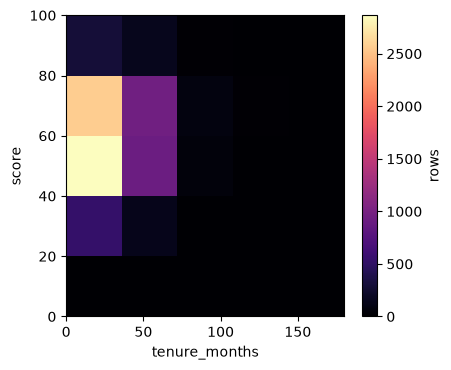

In [ ]:
plt.figure(figsize=(4.6, 3.8))
plt.pcolormesh(ye, xe, J, cmap="magma")   # edges for x, then y, then the counts
plt.colorbar(label="rows")
plt.xlabel("tenure_months")
plt.ylabel("score")
plt.tight_layout()
plt.show()

`pcolormesh(X, Y, C)` treats the first index of `C` as the **y** direction and the second as x. `histogram2d` put the first argument on the first index. Passing the tenure edges as X and the score edges as Y therefore lines up, because score is `J`'s first index. Passed the other way round, the figure comes out transposed with no error. Both axes are therefore labelled. One cell is also checked against the printed matrix.

With many rows, a joint histogram replaces the scatter plot. It counts the rows in each cell instead of drawing each row. The density then stays readable where points would overlap.

## 14 Comparing groups

A label splits the rows into classes. We can compute any count, summary or figure once per class to see how the classes differ. Here the label is `churn`. Its two classes are the customers who stayed and the customers who left.

### Class balance

In [ ]:
churn = np.array([int(r["churn"]) for r in records])   # 1 for a customer who left

print(np.bincount(churn))                   # rows per class
print(np.bincount(churn) / len(churn))

[5716 3284]
[0.63511111 0.36488889]


`np.bincount` counts how often each of 0, 1, 2 and so on occurs. On a 0/1 label it returns the size of each class. Of the 9000 customers, 63.5 per cent stayed. A model that predicts "stayed" for every row, whatever its features, is therefore right 63.5 per cent of the time. The share of the largest class is the baseline an accuracy on this label is compared with. A label whose classes differ a lot in size is called **imbalanced**.

### The mean of a 0/1 column

In [ ]:
print("churn.mean()", round(float(churn.mean()), 4))   # the share of ones

for name in ["basic", "standard", "premium", "legacy"]:
    k = plan == name
    print(f"{name:<9} n={k.sum():>5}  churn rate {churn[k].mean():.3f}")

churn.mean() 0.3649
basic     n= 3103  churn rate 0.334
standard  n= 2819  churn rate 0.419
premium   n= 1828  churn rate 0.181
legacy    n= 1250  churn rate 0.589


The sum of a 0/1 column is its number of ones. Its mean is therefore the share of ones. A grouped mean of the label is the rate of the label within each group. Customers on the legacy plan left at three times the rate of customers on the premium plan. The column `plan` is therefore a useful feature for a classifier.

### Means per class

In [ ]:
for name, v in [("age", age), ("income", income), ("tenure", tenure), ("score", score)]:
    stayed = np.nanmean(v[churn == 0])
    left = np.nanmean(v[churn == 1])
    print(f"{name:<7} stayed {stayed:9.2f}   left {left:9.2f}")

age     stayed     44.07   left     41.46
income  stayed  33521.97   left  28923.53
tenure  stayed     29.96   left     21.10
score   stayed     62.02   left     53.31


The customers who left had been customers for 9 months less on average and scored 9 points lower. A difference between two means measures how far apart the centres of the two classes are. It does not measure how far the two distributions overlap. The histograms of the two classes show the overlap.

### plt.subplots

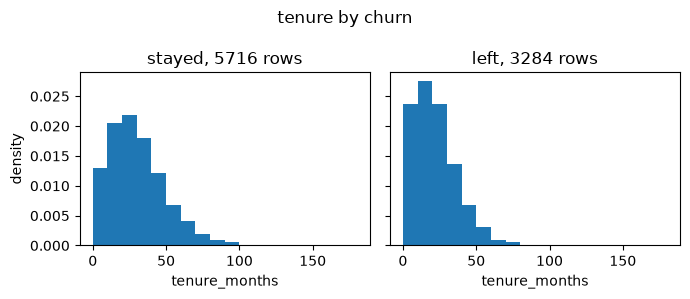

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3), sharex=True, sharey=True)

for ax, label, name in zip(axes, [0, 1], ["stayed", "left"]):
    k = churn == label                  # tenure has no gaps, so no NaN mask
    ax.hist(tenure[k], bins=18, range=(0, 180), density=True)
    ax.set_title(f"{name}, {k.sum()} rows")
    ax.set_xlabel("tenure_months")
axes[0].set_ylabel("density")
fig.suptitle("tenure by churn")
fig.tight_layout()
plt.show()

`plt.subplots(nrows, ncols)` creates a figure divided into a grid of plotting areas and returns two objects. The first is the `Figure`. The second holds the plotting areas. Matplotlib calls a plotting area an `Axes`. One row of two gives a NumPy array of two `Axes`. A grid gives a two-dimensional array indexed as `axes[row, col]`. A single plot gives one `Axes` rather than an array. `fig.suptitle` puts one title above all the panels.

Each `Axes` has the plotting functions as methods, such as `ax.hist` and `ax.scatter`. The functions that set a property take a `set_` prefix. `plt.xlabel` becomes `ax.set_xlabel`. `plt.title` becomes `ax.set_title`. Matplotlib calls this the explicit Axes interface. Calls such as `plt.hist` and `plt.xlabel` use the implicit pyplot interface. It draws on whichever Axes was created last. With several panels in one figure, the explicit form names the panel every call draws on.

`sharex=True` and `sharey=True` give every panel the same axis limits. Without them each panel is scaled to its own data. The tallest bar then reaches the top of every panel. Two different distributions can look alike.

**Try it.** Draw the same two panels for `score`. It has gaps. The mask therefore also has to remove them.

### density=True for groups of different size

The two classes have 5716 and 3284 rows. Raw counts therefore mix the size of each class into its shape. In the bin from 10 to 20 months the counts are 1169 for the customers who stayed and 907 for those who left. As a share of each class the order reverses. That bin holds 20.5 per cent of the customers who stayed and 27.6 per cent of those who left. `density=True` divides each histogram by its own number of rows and by the bin width. The bars of the two classes can then be compared directly.

In [ ]:
for label, name in [(0, "stayed"), (1, "left")]:
    t = tenure[churn == label]
    n = int(((t >= 10) & (t < 20)).sum())
    print(f"{name:<7} {n:>5} of {len(t)} rows in 10 to 20 months, {100 * n / len(t):.1f} per cent")

stayed   1169 of 5716 rows in 10 to 20 months, 20.5 per cent
left      907 of 3284 rows in 10 to 20 months, 27.6 per cent


### Legends and grids

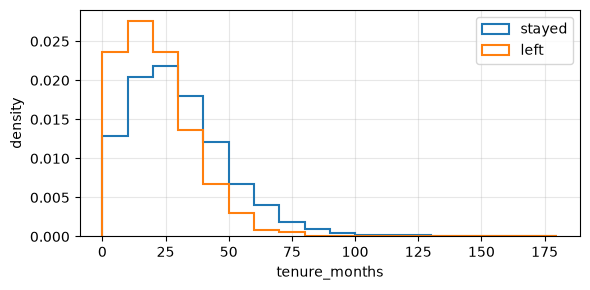

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3))
for label, name in [(0, "stayed"), (1, "left")]:
    ax.hist(tenure[churn == label], bins=18, range=(0, 180), density=True,
            histtype="step", linewidth=1.5, label=name)
ax.set_xlabel("tenure_months")
ax.set_ylabel("density")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

The code draws both classes on one `Axes`. `histtype="step"` draws each histogram as an outline. Neither then covers the other. `label=` names each call. `ax.legend()` draws a key from those names. `ax.grid(alpha=0.3)` adds faint grid lines to read the heights against.

### Scatter plots by class

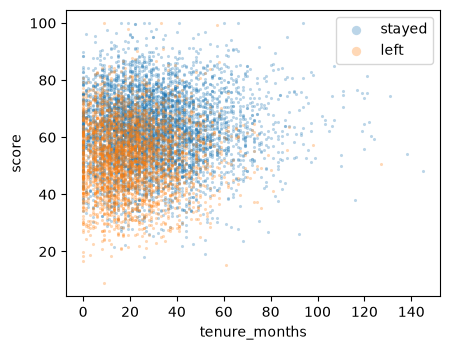

In [ ]:
fig, ax = plt.subplots(figsize=(4.6, 3.6))
for label, name in [(0, "stayed"), (1, "left")]:
    k = (churn == label) & ~np.isnan(score)
    ax.scatter(tenure[k], score[k], s=5, alpha=0.3, linewidths=0, label=name)
ax.set_xlabel("tenure_months")
ax.set_ylabel("score")
ax.legend(markerscale=3)
fig.tight_layout()
plt.show()

One `scatter` call per class, each with its own colour and label, shows two features and the label in one figure. At `s=5` the markers in the key are hard to see. `markerscale=3` enlarges them. The customers who left lie towards short tenure and low score. The two clouds overlap over most of the plane. To colour the points by a numeric column instead, the column goes to the `c` argument and a colour map to `cmap`, as in `sc = ax.scatter(x, y, c=v, cmap="viridis")`. `fig.colorbar(sc, ax=ax)` then adds the colour scale.

## 15 Encoding a table for a neural network

A neural network computes weighted sums of its inputs. Every input has to be a number, with no value missing. Training moves each weight by a step proportional to the input it multiplies. The columns therefore also have to be on comparable scales. The register has three text columns, gaps in three numeric columns and an income in tens of thousands next to a score out of 100. We one-hot encode the text columns, fill each gap with the median of its column, mark the filled cells in indicator columns and standardise the numeric columns. We then join everything into one float32 matrix.

### Requirements on the input

- **Every input is a number.** Each input is multiplied by a weight. A string cannot be.
- **No input is missing.** One NaN makes every weighted sum it enters NaN. During training it spreads to every weight.
- **The inputs are on comparable scales.** A column in tens of thousands next to one in tens needs weights about a thousand times apart. Its weight is also moved by training steps about a thousand times larger. No single step size therefore suits both.

### Text columns

In [ ]:
region = np.array([r["region"] for r in records])
print(region[:3])

try:
    region[:3] * 0.5
except TypeError as err:          # NumPy raises UFuncTypeError, a kind of TypeError
    print(type(err).__name__, ":", err)

['North' 'Eastfield' 'Midland']
UFuncTypeError : ufunc 'multiply' did not contain a loop with signature matching types (dtype('<U9'), dtype('float64')) -> None


NumPy has no multiplication of a string by a number. A text column therefore cannot enter a weighted sum.
It has to become one or more numeric columns first.

### Integer codes

The integer codes replace each region with its position in the list. A single weight `w` times that code gives the six regions 0, `w`, `2w`, `3w`, `4w` and `5w`. These are equal steps, in the order the list happens to have. The cell below prints the mean score of each region in code order.

In [ ]:
for code, name in enumerate(CATEGORIES["region"]):
    sel = (region == name) & ~np.isnan(score_c)
    print(f"code {code}  {name:<10} mean score {score_c[sel].mean():6.2f}")

code 0  North      mean score  51.28
code 1  Harbour    mean score  60.76
code 2  Midland    mean score  58.55
code 3  Eastfield  mean score  65.20
code 4  Southgate  mean score  55.65
code 5  Upland     mean score  67.49


The means rise and fall alternately. No value of `w` produces that pattern from the codes.

### One-hot encoding

In [ ]:
names = CATEGORIES["region"]
onehot = np.stack([(region == n).astype(np.float32) for n in names], axis=1)

print("shape      ", onehot.shape)
for row, name in zip(onehot[:3], region[:3]):
    print("           ", row, name)
print("row sums   ", np.unique(onehot.sum(axis=1)))
print("column sums", onehot.sum(axis=0))

shape       (9000, 6)
            [1. 0. 0. 0. 0. 0.] North
            [0. 0. 0. 1. 0. 0.] Eastfield
            [0. 0. 1. 0. 0. 0.] Midland
row sums    [1.]
column sums [1928. 1634. 1798. 1262. 1417.  961.]


Each region becomes a column of its own, 1 in the rows of that region and 0 everywhere else.
`np.stack` joins the six `(9000,)` columns along a new axis. `axis=1` makes that the second axis. The result has one row per customer. Every column gets its own weight. Every region therefore contributes an amount of its own. The column order comes from `CATEGORIES["region"]` and has to be
the same every time the encoding is built.

### Dropping incomplete rows

Listwise deletion keeps the 7403 rows with no gap and discards 1597, with every value that was
present in them. It also does not help once the network is in use. A new customer with no recorded income still needs a number in that cell.

### Imputation with the median

In [ ]:
num = np.stack([column(c) for c in NUMERIC], axis=1)     # (9000, 4) float64, NaN in the gaps
med = np.nanmedian(num, axis=0)
filled = np.where(np.isnan(num), med, num)      # (9000, 4) v (4,) -> (9000, 4)

print("medians         ", dict(zip(NUMERIC, med.tolist())))
print("row 15 filled   ", filled[15].tolist())
print("any NaN left    ", np.isnan(filled).any())
print(f"income std       {np.nanstd(num[:, 1]):.0f} before, {filled[:, 1].std():.0f} after")

medians          {'age': 43.0, 'income': 28210.26, 'tenure_months': 24.0, 'score': 59.1}
row 15 filled    [52.0, 28210.26, 23.0, 65.8]
any NaN left     False
income std       15492 before, 14855 after


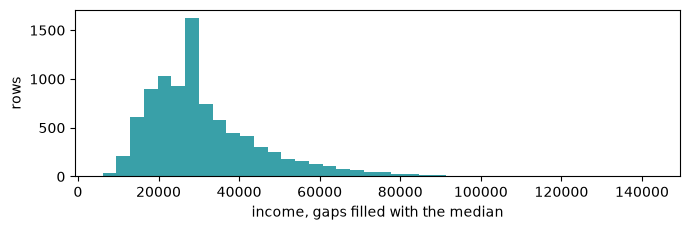

In [ ]:
#@title Figure: income after median imputation  { display-mode: "form" }
income_all = column("income")
income_filled = np.where(np.isnan(income_all), np.nanmedian(income_all), income_all)
plt.figure(figsize=(7, 2.4))
plt.hist(income_filled, bins=40, color="#39a0a8")
plt.xlabel("income, gaps filled with the median")
plt.ylabel("rows")
plt.tight_layout()
plt.show()

**Imputation** replaces each gap with a value computed from the column. The median is used because a long tail moves the mean and not the
median. `np.where(condition, a, b)` takes `a` where the condition holds and `b` elsewhere. `med`, shape `(4,)`, broadcasts across the rows. Filling places 763 incomes exactly at the median. The filled column is therefore narrower than the recorded one. Nothing in it distinguishes a filled value from a recorded one.

### Indicator columns

In [ ]:
flags = np.isnan(num[:, [0, 1, 3]]).astype(np.float32)   # age, income and score have gaps

print("shape     ", flags.shape)
print("row 15    ", flags[15])
print("per column", flags.sum(axis=0))

shape      (9000, 3)
row 15     [0. 1. 0.]
per column [564. 763. 373.]


Indicator columns add one 0/1 column for each column that had gaps, with 1 where the value was filled
in. Whether a value is missing can itself be related to the label. That information is lost when only the filled value is kept.
Filling the gaps and adding these columns is called the **missing-indicator method**.

### Standardisation

In [ ]:
z = (filled - filled.mean(axis=0)) / filled.std(axis=0)   # (9000, 4) v (4,) -> (9000, 4)

print("std before", filled.std(axis=0).round(2).tolist())
print("std after ", z.std(axis=0).round(2).tolist())
print("row 15    ", z[15].round(2).tolist())

std before [12.89, 14854.88, 18.51, 12.89]
std after  [1.0, 1.0, 1.0, 1.0]
row 15     [0.69, -0.22, -0.2, 0.54]


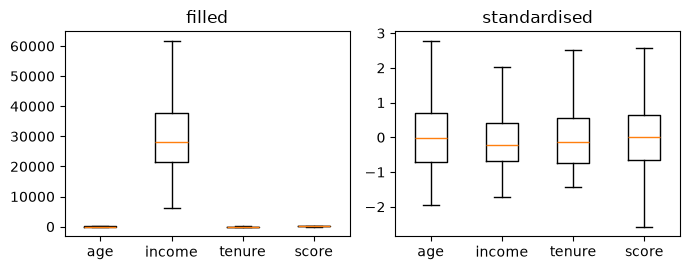

In [ ]:
#@title Figure: the four numeric columns before and after standardising  { display-mode: "form" }
num = np.stack([column(c) for c in ["age", "income", "tenure_months", "score"]], axis=1)
filled = np.where(np.isnan(num), np.nanmedian(num, axis=0), num)
z = (filled - filled.mean(axis=0)) / filled.std(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8))
axes[0].boxplot(filled, showfliers=False)
axes[0].set_title("filled")
axes[1].boxplot(z, showfliers=False)
axes[1].set_title("standardised")
for ax in axes:
    ax.set_xticks(range(1, 5), ["age", "income", "tenure", "score"])
fig.tight_layout()
plt.show()

The standard deviation of income is about 1150 times that of score. With equal weights, income therefore dominates every weighted sum. **Standardising** subtracts each column's mean and divides by its standard deviation. Afterwards every column has mean 0 and standard deviation 1. A value then reads as a number of standard deviations from the mean.

### The feature matrix

In [ ]:
blocks = [z, flags]
for c in CATEGORICAL:
    v = np.array([r[c] for r in records])
    blocks.append(np.stack([(v == name).astype(np.float32) for name in CATEGORIES[c]], axis=1))
X = np.concatenate(blocks, axis=1).astype(np.float32)

print("shape    ", X.shape, "  4 standardised + 3 indicators + 6 + 4 + 3 one-hot")
print("any NaN  ", np.isnan(X).any())
print("dtype    ", X.dtype)
print("first row", X[0].round(2))

shape     (9000, 20)   4 standardised + 3 indicators + 6 + 4 + 3 one-hot


any NaN   False
dtype     float32
first row [-0.4  -0.63  1.1   0.05  0.    0.    0.    1.    0.    0.    0.    0.
  0.    0.    1.    0.    0.    0.    0.    1.  ]


`np.concatenate` joins arrays along an axis they already have, here the columns. `X` meets the three requirements: every cell is a number, no cell is missing and the numeric columns share one scale.

The medians, means and standard deviations come from all 9000 rows here. Once the rows are split
into a set to train on and a set to test on, they are computed on the training rows only and reused
unchanged on the test rows.

## 16 Loop forms and array equivalents

In the table below we write the counting, summarising, binning and encoding loops as array expressions. Each expression works on a column `v`, two or three columns `x`, `y` and `z`, a 0/1 column `label` or a matrix `m` of numeric columns. The summaries skip missing values. A single gap then does not make their result NaN.

| What the loop does | As an array expression |
|---|---|
| Rows in one category | `(plan == "premium").sum()` |
| Rows in every category, in a chosen order | `[(plan == n).sum() for n in CATEGORIES["plan"]]` |
| Distinct categories and their counts | `np.unique(plan, return_counts=True)` |
| How many values are missing | `np.isnan(v).sum()` |
| How many are present | `(~np.isnan(v)).sum()` |
| Mean, skipping the gaps | `np.nanmean(v)` |
| Median and spread, skipping the gaps | `np.nanmedian(v)`, `np.nanstd(v)` |
| Extremes, skipping the gaps | `np.nanmin(v)`, `np.nanmax(v)` |
| Quartiles | `np.quantile(v[~np.isnan(v)], [.25, .5, .75])` |
| Mean within one group | `v[(cat == name) & ~np.isnan(v)].mean()` |
| Count values in one interval | `((v >= lo) & (v < hi)).sum()` |
| Count values in every interval | `np.histogram(v, bins=20, range=(0, 100))` |
| The bin a value falls into | `np.digitize(v, edges)` |
| Counts scaled to unit area | `np.histogram(v, bins=20, density=True)` |
| Rows where two columns are both present | `~np.isnan(x) & ~np.isnan(y)` |
| Count rows in a cell of a grid | `np.histogram2d(x, y, bins=[5, 5])` |
| Linear agreement of two columns | `np.corrcoef(x[k], y[k])[0, 1]` |
| All pairwise correlations at once | `np.corrcoef(np.stack([x, y, z]))` |
| Rows in each class of a 0/1 label | `np.bincount(label)` |
| Share of ones in a 0/1 column | `label.mean()` |
| Mean of a column within each class | `[np.nanmean(v[label == c]) for c in (0, 1)]` |
| One 0/1 column per category | `np.stack([(v == n).astype(np.float32) for n in names], axis=1)` |
| Each column's gaps filled with its median | `np.where(np.isnan(m), np.nanmedian(m, axis=0), m)` |
| Where the gaps were, as 0/1 columns | `np.isnan(m).astype(np.float32)` |
| Every column standardised, after filling | `(m - m.mean(axis=0)) / m.std(axis=0)` |

### Further reading

- [The csv module](https://docs.python.org/3/library/csv.html), for `DictReader`, dialects and quoting.
- [Statistics routines](https://numpy.org/doc/stable/reference/routines.statistics.html), with the NaN-ignoring function beside each ordinary one.
- [isnan](https://numpy.org/doc/stable/reference/generated/numpy.isnan.html) and [unique](https://numpy.org/doc/stable/reference/generated/numpy.unique.html).
- [pyplot.bar](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.bar.html), for the arguments the example above does not use.
- [Imputation of missing values](https://scikit-learn.org/stable/modules/impute.html), scikit-learn's guide to filling strategies and to marking the filled values.
- [histogram](https://numpy.org/doc/stable/reference/generated/numpy.histogram.html) and [histogram2d](https://numpy.org/doc/stable/reference/generated/numpy.histogram2d.html), including the `weights` and `density` arguments.
- [corrcoef](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html), and [cov](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) underneath it.
- [pyplot.hist](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html), [scatter](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) and [pcolormesh](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.pcolormesh.html).
- [pyplot.subplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html), and [Matplotlib Application Interfaces](https://matplotlib.org/stable/users/explain/figure/api_interfaces.html) on the explicit and the implicit interface.